# Comparing Effective Radius vs Velocity Dispersion
We'll look at one of the fundamental plane relations, effective radius vs velocity dispersion.

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [19]:
# By now standard code that merges the three excel data sheets.
morph = pd.read_csv('SAMI_Visual_Morphology/samiDR3VisualMorphology.csv')
cat = pd.read_csv('SAMI_Input_Cat_Cluster/samiDR3InputCatClusters.csv')
kin = pd.read_csv('SAMI_Kinematics/samiDR3StelKin.csv')

morphcat = pd.merge(morph, cat, on='catid', how='inner')
df = pd.merge(morphcat, kin, on='catid', how='inner')
print('Final Data Set', len(df))

Final Data Set 962


In [ ]:
# Now, the important headers are:
# -- type 0 or 0.5 from Visual Morphology
# -- r_e for effective radius
# -- sigma_re, sigma_re_err, sigma_3kpc_round, sigma_3kpc_round_err, 
#    sigma_1_4_arcsecond, sigma_1_4_arcsecond_err, sigma_2_arcsecond, sigma_2_arcsecond_err, 
#    sigma_3_arcsecond, sigma_3_arcsecond_err, sigma_4_arcsecond, sigma_4_arcsecond_err.

#NOTE dropping NaN values for sigma_re and r_e here now
df = df.dropna(subset = ['type', 'r_e', 'sigma_re', 'z_spec']) # won't drop NaN for different sigma_re just yet.
# now lets do necessary checks such as unique catids, and ensuring postive values 
# for r_e, sigma_re and z_spec
uniquecatids = df['catid'].nunique()
print('Number of unique catid values in df:', uniquecatids)
print("Does unique catid values = total number of rows in df?", uniquecatids == len(df))
if df['r_e'].min() > 0:
    print("There are no negative values in the r_e column, good to go :)")
else: 
    print("There are negative values in the r_e column, filter before taking logarithm")

if df['sigma_re'].min() > 0:
    print("There are no negative values in the sigma_re column, good to go :)")
else: 
    print("There are negative values in the sigma_re column, filter before taking logarithm")

if df['z_spec'].min() > 0:
    print("There are no negative values in the z_spec column, good to go :)")
else: 
    print("There are negative values in the z_spec column, filter before taking logarithm")




# This has dropped one 0.0 galaxy and 2 0.5 galaxies -- good!
el_zero = df[df['type'] == 0];
el_half = df[df['type'] == 0.5];

# First lets get a feel for the redshift range (z_spec)
el_zero_min = el_zero['z_spec'].min()
el_zero_max = el_zero['z_spec'].max()
el_half_min = el_half['z_spec'].min()
el_half_max = el_half['z_spec'].max()
# define speed of light (km/s) for ease of use and hubble const (km/s/Mpc)
c = 300000
H_0 = 70
# New idea convert arcseconds to kpc and plot see if helps. Then maybe try log.
# As with arcseconds looking at how much of sky it covers not the galaxies actual size.
# With Redshift we use eqn for converting arcseconds to MPC the times by 1000 (shown in eqn below)
# ie. R_E (kpc)r_e(arcsec) * D_A (MPC) * 1000 / 206265 where 206265 is number of arcseconds in radian.
# To get D_A (MPC) we use D_A = c * z / (H_0 * (1+z))

D_A_el_zero = c * el_zero['z_spec'] / (H_0 * (1 + el_zero['z_spec'])) # in Mpc
D_A_el_half = c * el_half['z_spec'] / (H_0 * (1 + el_half['z_spec'])) # in Mpc

R_E_el_zero = el_zero['r_e'] * D_A_el_zero * 1000 /206265 # in kpc
R_E_el_half = el_half['r_e'] * D_A_el_half * 1000 /206265 # in kpc

print("min and max redshift for type 0.0 galaxies: ", el_zero_min, el_zero_max)
print("min and max redshift for type 0.5 galaxies: ", el_half_min, el_half_max)

print(f"We have {len(el_zero)} type 0.0 galaxies and {len(el_half)} type 0.5 galaxies.");

Number of unique catid values in df: 745
Does unique catid values = total number of rows in df? True
There are no negative values in the r_e column, good to go :)
There are no negative values in the sigma_re column, good to go :)
There are no negative values in the z_spec column, good to go :)
min and max redshift for type 0.0 galaxies:  0.026790852 0.066114955
min and max redshift for type 0.5 galaxies:  0.026706906 0.061265714
We have 107 type 0.0 galaxies and 96 type 0.5 galaxies.


In [21]:
el_zero_re = pd.to_numeric(el_zero['r_e'], errors='coerce');
el_half_re = pd.to_numeric(el_half['r_e'], errors='coerce');

el_zero_sigma_re = pd.to_numeric(el_zero['sigma_re'], errors='coerce');
el_half_sigma_re = pd.to_numeric(el_half['sigma_re'], errors='coerce');
el_zero_sigma_re_err = pd.to_numeric(el_zero['sigma_re_err'], errors='coerce');
el_half_sigma_re_err = pd.to_numeric(el_half['sigma_re_err'], errors='coerce');

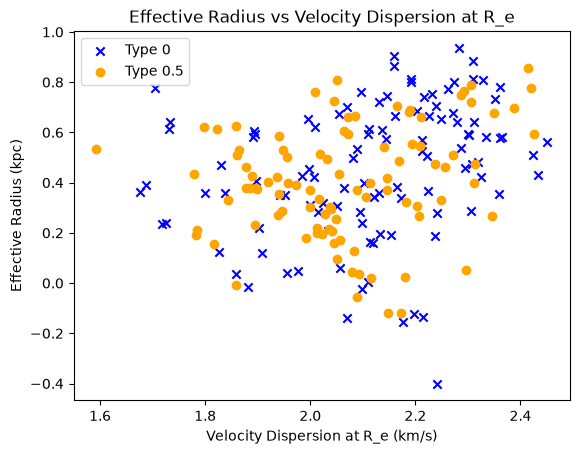

In [ ]:
# Time to plot! Let's see... why is there no trend?
"""
plt.scatter(el_zero_sigma_re, el_zero_re, marker='x', color='blue', label='Type 0')
plt.scatter(el_half_sigma_re, el_half_re, marker='o', color='orange', label='Type 0.5');
#plt.errorbar(el_zero_sigma_re, el_zero_re, xerr=el_zero_sigma_re_err, fmt='none', color='blue', label='Type 0', linestyle='none')
#plt.errorbar(el_half_sigma_re, el_half_re, xerr=el_half_sigma_re_err, fmt='none', color='orange', label='Type 0.5', linestyle='none');
plt.title("Effective Radius vs Velocity Dispersion at R_e")
plt.xlabel("Velocity Dispersion at R_e (km/s)")
plt.ylabel("Effective Radius (arcsec)")
plt.legend();
plt.show()

# Ill try taking log of both see if that works
#NOTE unsuccessful still no clear trend seen

plt.scatter(np.log10(el_zero_sigma_re), np.log10(el_zero_re), marker='x', color='blue', label='Type 0')
plt.scatter(np.log10(el_half_sigma_re), np.log10(el_half_re), marker='o', color='orange', label='Type 0.5');
#plt.errorbar(el_zero_sigma_re, el_zero_re, xerr=el_zero_sigma_re_err, fmt='none', color='blue', label='Type 0', linestyle='none')
#plt.errorbar(el_half_sigma_re, el_half_re, xerr=el_half_sigma_re_err, fmt='none', color='orange', label='Type 0.5', linestyle='none');
plt.title("Effective Radius vs Velocity Dispersion at R_e")
plt.xlabel("Velocity Dispersion at R_e (km/s)")
plt.ylabel("Effective Radius (arcsec)")
plt.legend();
plt.show()
"""

#NOTE I actually did this above where D_A is
# New idea convert arcseconds to kpc and plot see if helps. Then maybe try log.
# As with arcseconds looking at how much of sky it covers not the galaxies actual size.
# With Redshift we use eqn for converting arcseconds to MPC the times by 1000 (shown in eqn below)
# ie. R_E (kpc)r_e(arcsec) * D_A (MPC) * 1000 / 206265 where 206265 is number of arcseconds in radian.
# To get D_A (MPC) we use D_A = c * z / (H_0 * (1+z))
 

plt.scatter(np.log10(el_zero_sigma_re), np.log10(R_E_el_zero), marker='x', color='blue', label='Type 0')
plt.scatter(np.log10(el_half_sigma_re), np.log10(R_E_el_half), marker='o', color='orange', label='Type 0.5');

#NOTE if use graph fix up units and labels 
plt.title("Effective Radius vs Velocity Dispersion at R_e")
plt.xlabel("Velocity Dispersion at R_e (km/s)")
plt.ylabel("Effective Radius (kpc)")
plt.legend();
plt.show()

In [25]:
#checking to see if there is a correlation in above graph
r_0 = np.log10(el_zero_sigma_re).corr(np.log10(R_E_el_zero))
print("Correlation coefficent, r of type 0.0 galaxies: ", r_0)

r_05 = np.log10(el_half_sigma_re).corr(np.log10(R_E_el_half))
print("Correlation coefficent, r of type 0.5 galaxies: ", r_05)

Correlation coefficent, r of type 0.0 galaxies:  0.2647928844875889
Correlation coefficent, r of type 0.5 galaxies:  0.23032691290855747


Number of Nan values in el_zero mu_within_1re column:  0
Number of Nan values in el_half mu_within_1re column:  0
Correlation coefficent, r of type 0.0 galaxies:  0.7112813290065536
Correlation coefficent, r of type 0.5 galaxies:  0.7198790450129537


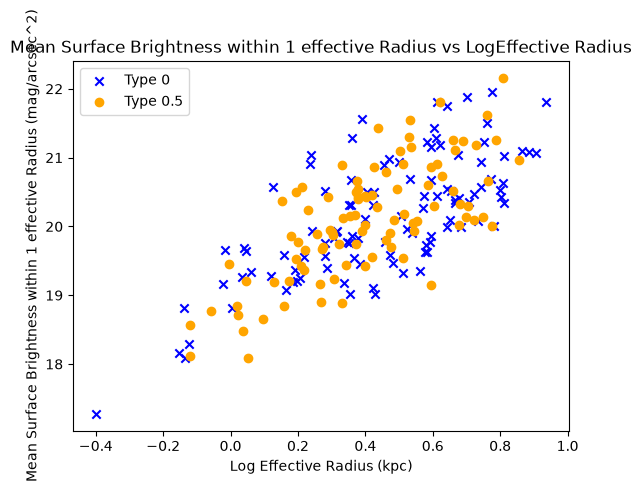

In [34]:
# Now goint to plot...
# First check how many NaN values in el_zero and el_half in mu_within_1re column

print("Number of Nan values in el_zero mu_within_1re column: ", el_zero['mu_within_1re'].isnull().sum())
print("Number of Nan values in el_half mu_within_1re column: ", el_half['mu_within_1re'].isnull().sum())

r_0 = el_zero['mu_within_1re'].corr(np.log10(R_E_el_zero))
r_05 = el_half['mu_within_1re'].corr(np.log10(R_E_el_half))
print("Correlation coefficent, r of type 0.0 galaxies: ", r_0)
print("Correlation coefficent, r of type 0.5 galaxies: ", r_05)

plt.scatter(np.log10(R_E_el_zero), el_zero['mu_within_1re'], marker='x', color='blue', label='Type 0')
plt.scatter(np.log10(R_E_el_half), el_half['mu_within_1re'], marker='o', color='orange', label='Type 0.5')

#NOTE if use graph fix up units and labels 
plt.title("Mean Surface Brightness within 1 effective Radius vs LogEffective Radius")
plt.ylabel("Mean Surface Brightness within 1 effective Radius (mag/arcsec^2)")
plt.xlabel("Log Effective Radius (kpc)")
plt.legend()
plt.show()